# 02 · EVER >30 a MOB 3: número y saldo

> **Datos del ejemplo: simulados.** Este notebook usa por defecto una cartera ficticia de seis cuentas para mostrar el flujo y los gráficos. Selecciona `MODO = 'plantilla'` para leer el extracto local. La plantilla inicial está vacía; no se incluyen resultados reales.

## Decisión
Comparar cohortes de tarjeta por mora temprana para investigar cambios de calidad y mezcla. Un resultado descriptivo no demuestra que una estrategia de originación haya causado la diferencia.

## Definición y supuestos a validar

Para cada cuenta $i$ y horizonte $h=3$, con días de mora observados $D_{i,m}$:

$$E_{i,h}=\mathbf{1}\left(\max_{m=1,\ldots,h}D_{i,m}>30\right).$$

El valor 30 exacto **no** cumple el evento. Por defecto MOB 0 no entra; puede incluirse con `include_mob0=True` si el contrato institucional lo exige. La población evaluable $A_h$ tiene registros y DPD conocidos en todos los MOB requeridos. Una cuenta faltante no se clasifica como sana.

$$\operatorname{EVER}^{N}_{h}=\frac{\sum_{i\in A_h}E_{i,h}}{|A_h|}, \qquad
\operatorname{EVER}^{\$}_{h}=\frac{\sum_{i\in A_h^B}B_{i,h}E_{i,h}}{\sum_{i\in A_h^B}B_{i,h}}.$$

$A_h^B$ contiene las cuentas evaluables con saldo de capital $B_{i,h}$ conocido, finito y no negativo en el horizonte. Se declara el tamaño de cada denominador y un saldo total cero deja la tasa en blanco. **El saldo expuesto no es pérdida.** Para cliente, el evento ocurre si alguna cuenta representada presenta evento; todas sus cuentas representadas deben ser evaluables, y el saldo suma sus cuentas solo cuando todos son válidos.

In [1]:
from pathlib import Path
import sys, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
base = Path.cwd()
if not (base / 'vintage_core.py').exists():
    root = next(p for p in [base, *base.parents] if (p / '03-financial-risk').is_dir())
    base = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(base))
from vintage_core import prepare_panel, build_vintage, summarize_vintage, GROUP
from demo_inputs import demo_panel
plt.rcParams.update({'figure.figsize':(10,4.8),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.2,'axes.axisbelow':True})
# Cambie a 'plantilla' para leer el CSV local; nunca cargue datos sensibles en Git.
MODO = 'demostracion'
assert MODO in ('demostracion', 'plantilla')
panel = demo_panel() if MODO == 'demostracion' else pd.read_csv(base/'plantilla_panel_mensual.csv')
print('MODO:',MODO.upper(),'— datos ficticios, no cartera real' if MODO=='demostracion' else '— plantilla o extracto del usuario')

MODO: DEMOSTRACION — datos ficticios, no cartera real


## 1. Construcción de cohortes maduras

El universo inicial son las cuentas representadas en el panel; el motor rechaza llaves duplicadas y conserva como no evaluables las cuentas con meses o DPD faltantes. La conciliación con la tabla de originación es necesaria para encontrar cuentas ausentes por completo.

In [2]:
accounts,clients=build_vintage(panel,horizon=3,include_mob0=False,balance_column='saldo_capital_cop')
if accounts.empty:
    print('No hay datos: cargar el extracto local o seleccionar demostración.')
else:
    print('Cuentas representadas:',len(accounts),'| Clientes representados:',len(clients))
    display(accounts[['corte_origen','loan_key','client_id','eligible','ever30','balance','balance_valid','missing_mobs']])
    print('Por cuenta');display(summarize_vintage(accounts))
    print('Por cliente');display(summarize_vintage(clients))

Cuentas representadas: 6 | Clientes representados: 6


,corte_origen,loan_key,client_id,eligible,ever30,balance,balance_valid,missing_mobs
0,2024-01,A,C01,True,True,120.0,True,
1,2024-01,B,C02,True,False,80.0,True,
2,2024-01,C,C03,False,<NA>,90.0,False,2
3,2024-02,D,C04,True,True,130.0,True,
4,2024-02,E,C05,True,False,70.0,True,
5,2024-02,F,C06,True,False,NaN,False,


Por cuenta


,corte_origen,universo,no_evaluables,n_maduros,n_eventos,ever_numero,n_saldo_valido,saldo_denominador,saldo_eventos,ever_saldo
0,2024-01,3,1,2,1,0.500000,2,200.0,120.0,0.60
1,2024-02,3,0,3,1,0.333333,2,200.0,130.0,0.65


Por cliente


,corte_origen,universo,no_evaluables,n_maduros,n_eventos,ever_numero,n_saldo_valido,saldo_denominador,saldo_eventos,ever_saldo
0,2024-01,3,1,2,1,0.500000,2,200.0,120.0,0.60
1,2024-02,3,0,3,1,0.333333,2,200.0,130.0,0.65


## 2. Curvas vintage comparables

Para comparar MOB 1, 2 y 3 se fija primero la población con observación completa hasta MOB 3. Para la curva por saldo se usa el saldo válido de **cada MOB**, por lo que su denominador monetario puede variar. No completar saldos faltantes con cero. Por el contrario, los cortes de cohortes que aún no maduran se muestran como no evaluables.

,corte_origen,mob,n_maduros,n_eventos,ever_numero,n_saldo_valido,saldo_denominador,ever_saldo
0,2024-01,1,2,0,0.000000,2,200.0,0.000000
1,2024-02,1,3,0,0.000000,3,270.0,0.000000
2,2024-01,2,2,1,0.500000,2,190.0,0.578947
3,2024-02,2,3,0,0.000000,3,260.0,0.000000
4,2024-01,3,2,1,0.500000,2,200.0,0.600000
5,2024-02,3,3,1,0.333333,2,200.0,0.650000


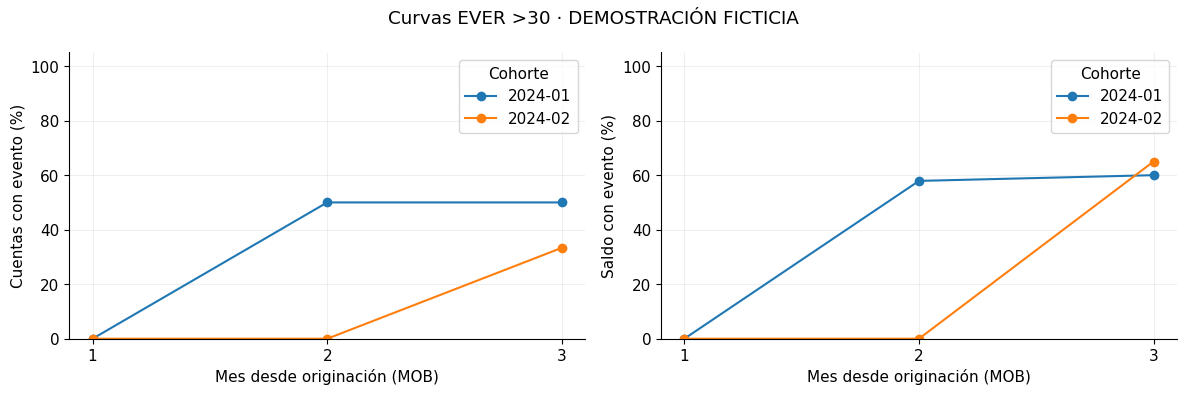

In [3]:
if not accounts.empty:
    keys=accounts.loc[accounts.eligible,GROUP]
    panel_fixed=panel.merge(keys,on=GROUP,how='inner',validate='many_to_one')
    curves=[]
    for h in (1,2,3):
        a,_=build_vintage(panel_fixed,horizon=h)
        if not a.empty:
            v=summarize_vintage(a);v['mob']=h;curves.append(v)
    curve=pd.concat(curves,ignore_index=True) if curves else pd.DataFrame()
    if not curve.empty:
        display(curve[['corte_origen','mob','n_maduros','n_eventos','ever_numero','n_saldo_valido','saldo_denominador','ever_saldo']])
        fig,axs=plt.subplots(1,2,figsize=(12,4),sharex=True)
        for cohort,g in curve.groupby('corte_origen'):
            g=g.sort_values('mob');axs[0].plot(g.mob,100*g.ever_numero,marker='o',label=str(cohort));axs[1].plot(g.mob,100*g.ever_saldo,marker='o',label=str(cohort))
        for ax,label in zip(axs,['Cuentas con evento (%)','Saldo con evento (%)']):
            ax.set(xlabel='Mes desde originación (MOB)',ylabel=label,xticks=[1,2,3],ylim=(0,105));ax.legend(title='Cohorte')
        fig.suptitle('Curvas EVER >30 · '+('DEMOSTRACIÓN FICTICIA' if MODO=='demostracion' else 'cuentas con MOB 3 completo'));plt.tight_layout();plt.show()
else: print('Sin observaciones para la curva vintage.')

## 3. Ejemplo de lectura y advertencias

En la demostración, una cuenta alcanza exactamente 30 días y no cuenta como evento; otra tiene DPD faltante y queda fuera del denominador de número. Un saldo desconocido se excluye solo del denominador monetario. La comparación por saldo puede cambiar por amortización y saldos faltantes aun si los eventos acumulados nunca disminuyen.

Antes de comparar segmentos por persona, estrategia, score o ubicación, adjuntar valores conocidos en originación con join uno a uno y fechas de disponibilidad. Para avances, definir aparte indicadores disponibles en MOB 1 o MOB 2 y no utilizarlos como predictores de originación. Calcular límites de confianza solo con un diseño de muestreo apropiado.

## 4. Fotografía OVER y primer evento

Para un corte $t$, $OVER_t^N=\sum_{i\in A_t}\mathbf{1}(D_{i,t}>30)/|A_t|$, donde $A_t$ solo incluye cuentas con DPD conocido en ese corte. A diferencia de EVER, OVER puede disminuir cuando una cuenta se pone al día. Si el saldo de una cuenta es válido, se pondera el OVER monetario por ese saldo; se reporta la cobertura de sus denominadores por separado. No atribuir el primer evento de mora a un avance sin comprobar el orden temporal y las hipótesis de identificación.

In [4]:
if not panel.empty and 'fecha_corte' in panel.columns:
    over=prepare_panel(panel).copy();over['fecha_corte']=pd.to_datetime(over.fecha_corte,errors='coerce')
    if over.fecha_corte.isna().any():
        raise ValueError('Hay fechas de corte nulas o inválidas')
    over=over.dropna(subset=['dpd']);over['evento']=over.dpd.gt(30)
    over['saldo_valido']=pd.to_numeric(over.saldo_capital_cop,errors='coerce')
    over.loc[~np.isfinite(over.saldo_valido) | (over.saldo_valido<0),'saldo_valido']=np.nan
    out=[]
    for date,g in over.groupby('fecha_corte'):
        weighted=g.dropna(subset=['saldo_valido']);den=weighted.saldo_valido.sum()
        out.append({'fecha_corte':date,'n_dpd_conocido':len(g),'n_eventos':int(g.evento.sum()),'over_numero':g.evento.mean(),
                    'n_saldo_valido':len(weighted),'saldo_total':den,
                    'over_saldo':weighted.loc[weighted.evento,'saldo_valido'].sum()/den if den>0 else np.nan})
    display(pd.DataFrame(out).tail(12))
else:
    print('OVER requiere observaciones y fecha_corte.')

,fecha_corte,n_dpd_conocido,n_eventos,over_numero,n_saldo_valido,saldo_total,over_saldo
0,2024-02-29,3,0,0.000000,3,290.0,0.00000
1,2024-03-31,5,1,0.200000,5,460.0,0.23913
2,2024-04-30,6,0,0.000000,6,550.0,0.00000
3,2024-05-31,3,1,0.333333,2,200.0,0.65000


El primer MOB de evento solo se obtiene para cuentas evaluables en la ventana seleccionada. Las cuentas sin evento se mantienen como «sin evento observado», no se asigna un mes arbitrario.

In [5]:
if not accounts.empty:
    complete=accounts.loc[accounts.eligible,GROUP]
    events=panel.merge(complete,on=GROUP,how='inner',validate='many_to_one')
    events=events[pd.to_numeric(events.mob,errors='coerce').between(1,3)]
    events=events[pd.to_numeric(events.dpd,errors='coerce').gt(30)]
    first=events.groupby(GROUP,dropna=False).mob.min().rename('primer_mob_evento').reset_index()
    print('Primer evento entre cuentas evaluables por MOB:')
    display(first.groupby('primer_mob_evento').size().rename('cuentas').to_frame())
    print('Sin evento observado:',int(accounts.eligible.sum()-len(first)))
else:
    print('Sin datos para primer evento.')

Primer evento entre cuentas evaluables por MOB:


,cuentas
primer_mob_evento,
2,1
3,1


Sin evento observado: 3


## Alcance y control de uso

La salida de demostración es ficticia y no valida desempeño de originación. Conciliar el panel con el universo de originación: una cuenta ausente por completo del panel, o descartada por un corte `as_of`, no aparece en el denominador. Un indicador mensual tampoco detecta necesariamente una mora intrames. Las reglas de población, DPD >30, MOB, saldos, cierres y castigos requieren aprobación institucional.